<a href="https://colab.research.google.com/github/Megh-Zyke/AI-teammate-for-Codebase-Insights/blob/main/CSE_595_HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

cse_595_hw_1_kaggle_path = kagglehub.competition_download('cse-595-hw-1-kaggle')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/cse-595-hw-1-kaggle/dev.csv
/kaggle/input/cse-595-hw-1-kaggle/train.csv
/kaggle/input/cse-595-hw-1-kaggle/test.csv


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from tqdm import tqdm
import math
import string
from scipy.sparse import csr_matrix
import seaborn as sns
from scipy.sparse import hstack
import random

In [ ]:
#Storing the paths of all train test and dev dataset
data_path = {}
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        data_path[filename[:-4]] = str(os.path.join(dirname, filename))
print(data_path)

{'dev': '/kaggle/input/cse-595-hw-1-kaggle/dev.csv', 'train': '/kaggle/input/cse-595-hw-1-kaggle/train.csv', 'test': '/kaggle/input/cse-595-hw-1-kaggle/test.csv'}


In [ ]:
train = pd.read_csv(str(data_path["train"]))

In [ ]:
#Feature Extraction
#Analysis of the dataset
train.head()

,id,model,generation,label
0,dfe2a93f-7c6b-4139-abfd-ca64519ad6cd,human,"""The Conjuring"" is one of the most thrilling h...",False
1,b6ae18d8-2d6c-4d44-8945-8d54f6a2ee26,human,The majority owner of embattled Russian oil fi...,False
2,291adf54-42ba-4e60-a8d2-dc96072a56a8,human,"Elissa Panush Benedek (born September 28, 193...",False
3,34efcdaa-9892-4b84-a573-533b3f36c933,human,Waterkeeper Alliance is a worldwide network of...,False
4,eb6173a7-25ea-44c3-b0c4-c2d5742419b0,gpt4,This academic paper presents the introduction ...,True


In [ ]:
print(f"Shape of the dataset - {train.shape}")
print(f"Number of null values present - {train.isnull().sum()}")

Shape of the dataset - (55002, 4)
Number of null values present - id            0
model         0
generation    0
label         0
dtype: int64


label
True     27502
False    27500
Name: count, dtype: int64


<BarContainer object of 2 artists>

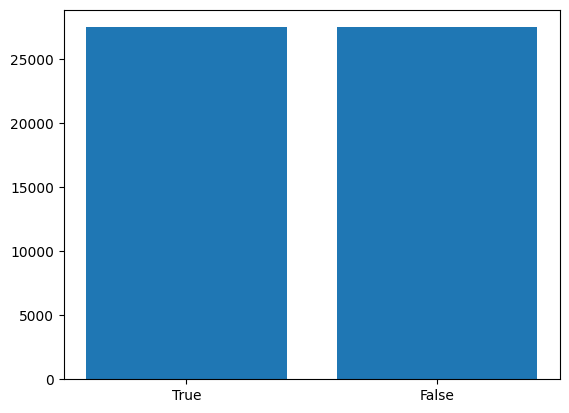

In [ ]:
label = train.label

print(label.value_counts())

plt.bar(label.value_counts().index.astype(str),label.value_counts().values )

In [ ]:
#Cleaning the data
final_df = train.iloc[:,[2,3]]
final_df.head()

,generation,label
0,"""The Conjuring"" is one of the most thrilling h...",False
1,The majority owner of embattled Russian oil fi...,False
2,"Elissa Panush Benedek (born September 28, 193...",False
3,Waterkeeper Alliance is a worldwide network of...,False
4,This academic paper presents the introduction ...,True


In [ ]:
#Printing 5 human generated text to understand the semnatic variation between LLM and Human written Text
human_generated = final_df[final_df["label"] == False].reset_index(drop=True)
llm_generated = final_df[final_df["label"] == True].reset_index(drop=True)

In [ ]:
for i in range(3,6):
    print(human_generated['generation'][i])
    print("\n")

Waterkeeper Alliance is a worldwide network of environmental organizations founded in 1999, in response to a growing movement of organizations with such names as Riverkeeper, Baykeeper and Soundkeeper. By December 2019, the group said it had grown to 571 members in 44 countries, with half the membership outside the U.S.; the alliance had added 050 groups in the last five years.  The original Riverkeeper, organized in 1983, started on the Hudson River in New York, in response to the destructive industrial pollution that was destroying the river. It soon was followed by Long Island Soundkeeper (led by Terry Backer), Delaware Riverkeeper, San Francisco Baykeeper, New York/New Jersey Baykeeper, and others. Today, Waterkeeper Alliance, which is based out of Manhattan, unites all Waterkeeper organizations, coordinating and covering issues affecting Waterkeepers that work to protect rivers, lakes, bays, sounds, and other water bodies around the world. In the United States, the east coast is s

In [ ]:
for i in range(3,9):
    print(llm_generated['generation'][i])
    print("\n")

A kaleidoscope of colors, swirling round,
A symphony of sounds, echoing profound.
The brush strokes dance, the melodies play,
As impressionism comes to life in every way.

In paint, the colors blend and fade,
A soft, ethereal glow, a shimmering shade.
The light and shadow intertwine,
A dreamlike scene, a work of art divine.

In music, chords and notes entwine,
A harmony of sound, a rhythm fine.
The melody flows, the beat sways,
A symphony of emotions, a musical ray.

In words, the poetry flows free,
A river of thoughts, a sea of glee.
The language dances, the rhythm sings,
A song of life, a joy that clings.

Together, the arts entwine,
A harmony of form, a symphony divine.
Impressionism in paint, in music, in words,
A celebration of life, a universe of birds.

The colors, sounds, and words combine,
A kaleidoscope of art, a symphony of the mind.
A world of beauty, a world of grace,
Impressionism, a wondrous, timeless place.




Music mogul Simon Fuller has sold his management company XI

In [ ]:
puncs = string.punctuation
print(puncs)
print(type(puncs))

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~
<class 'str'>


In [ ]:
#Extracting the most common punctuations used in human generated code
used_puncs = []
for text in human_generated['generation']:
    used_puncs.extend([ch for ch in text if ch in puncs])

count_punc = Counter(used_puncs)

In [ ]:
print(count_punc)

Counter({',': 454108, '.': 402273, '-': 102652, "'": 97577, '"': 62379, ')': 37152, '(': 36672, '/': 34456, ';': 23500, ':': 16472, '<': 13691, '>': 13680, '?': 11755, '$': 10894, '!': 10763, '%': 4784, '\\': 4429, '}': 2564, '{': 2562, '*': 2549, '&': 2427, '_': 2316, '^': 869, ']': 696, '[': 694, '=': 685, '+': 645, '#': 504, '~': 470, '`': 426, '|': 270, '@': 27})


In [ ]:
#Extracting the most common punctuations used in llm generated code
used_puncs_llm = []
for text in llm_generated['generation']:
    used_puncs.extend([ch for ch in text if ch in puncs])

count_punc_llm = Counter(used_puncs)
print(count_punc_llm)

Counter({',': 812923, '.': 726974, "'": 181591, '-': 179070, '"': 108966, ')': 61055, '(': 59625, '/': 57987, ':': 34185, ';': 30369, '?': 21620, '>': 20777, '!': 18812, '$': 14671, '<': 14148, '*': 10851, '%': 7034, '\\': 6268, '_': 5621, ']': 4518, '[': 4504, '=': 4348, '&': 4158, '}': 4133, '{': 4097, '#': 2504, '^': 1878, '+': 1345, '|': 943, '`': 728, '~': 726, '@': 198})


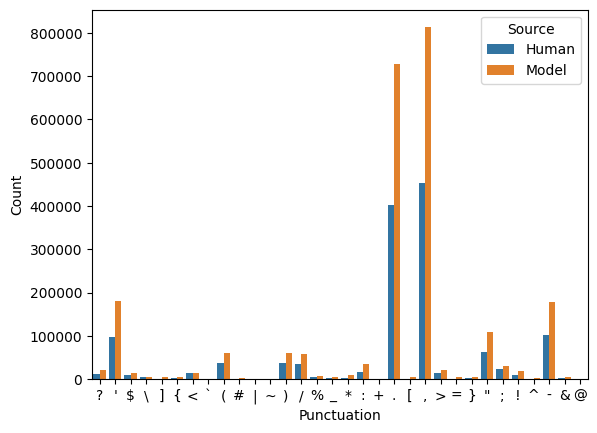

In [ ]:
#Visualization of the use of puncuations
data = []
for punc in set(count_punc.keys()) | set(count_punc_llm.keys()):
    data.append({"Punctuation": punc, "Count": count_punc.get(punc, 0), "Source": "Human"})
    data.append({"Punctuation": punc, "Count": count_punc_llm.get(punc, 0), "Source": "Model"})

df = pd.DataFrame(data)

sns.barplot(x="Punctuation", y="Count", hue="Source", data=df)
plt.show()

In [ ]:
human_text_lens = []
llm_len = []

for data in human_generated['generation']:
    human_text_lens.append(len(data.split()))



for data in llm_generated['generation']:
    llm_len.append(len(data.split()))

print(f"Average length of the content written by humans is {math.floor(np.mean(human_text_lens))}\nMedian length of the content written by humans is {math.floor(np.median(human_text_lens))}")
print(f"Average length of the content written by llms is {math.floor(np.mean(llm_len))}\nMedian length of the content written by llms is {math.floor(np.median(llm_len))}")


Average length of the content written by humans is 288
Median length of the content written by humans is 225
Average length of the content written by llms is 229
Median length of the content written by llms is 223


In [ ]:
def tokenize(input : str):
    return input.split(" ")

In [ ]:
data_1_token = tokenize(final_df['generation'][0])
print(data_1_token)

['"The', 'Conjuring"', 'is', 'one', 'of', 'the', 'most', 'thrilling', 'horror', 'film', 'to', 'have', 'come', 'out', 'in', 'recent', 'times.', 'It', 'is', 'up', 'there', 'with', '"Sinister"', 'as', 'one', 'of', 'the', 'scariest', 'films', 'I', 'have', 'watched.', 'Since', "it's", 'based', 'off', 'of', '"true', 'events",', 'it', 'makes', 'it', 'even', 'more', 'interesting.', 'I', "can't", 'quite', 'give', 'it', 'a', 'full', '10', 'star', 'rating', 'because', 'it', 'does', 'have', 'quite', 'a', 'few', 'jump', 'scares,', 'but', 'at', 'least', 'a', 'good', 'portion', 'of', 'those', 'jump', 'scares', 'add', 'to', 'the', 'atmosphere', 'of', 'this', 'movie.', 'If', 'you', 'are', 'a', 'first', 'time', 'watcher', 'of', 'this', 'movie,', 'it', 'will', 'certainly', 'disturb', 'you', 'for', 'a', 'while.', 'It', "doesn't", 'stick', 'with', 'me', 'like', '"Sinister"', 'does', 'long', 'after,', 'but', 'The', 'Conjuring', 'is', 'a', 'fun', 'watch', 'and', 'I', 'always', 'love', 'coming', 'back', 'for'

In [ ]:
#Generating a Dense Vector Representation of the tokens of the first data
vocab_ = list(set(data_1_token))
vocab_size_ = len(vocab_)

In [ ]:
print(f"The Vocabulary size in the first example is {vocab_size_}")
print(vocab_)

The Vocabulary size in the first example is 93
['first', "can't", 'films', 'scares,', 'scares', 'you', 'in', 'star', 'back', 'does', 'few', 'me', 'now', 'while.', 'off', 'give', 'this', 'a', 'watcher', 'recent', 'love', 'with', 'fun', 'more', 'watched.', 'jump', 'the', 'there', 'are', 'have', 'quite', 'If', 'horror', "it's", 'good', 'of', 'based', "doesn't", 'stick', 'will', 'events",', 'always', 'to', 'movie,', '"The', 'like', 'Since', 'rating', 'interesting.', '"true', 'but', 'rewatch', 'portion', 'Conjuring"', 'even', 'for', 'The', 'up', 'film', 'movie.', 'time', 'is', 'out', 'and', 'every', 'coming', 'atmosphere', 'It', 'least', 'it', 'I', 'as', 'Conjuring', 'one', 'come', 'times.', 'disturb', 'scariest', 'makes', 'at', 'watch', 'add', 'full', 'most', 'thrilling', 'because', 'certainly', 'then.', 'long', 'those', 'after,', '10', '"Sinister"']


In [ ]:
def better_tokenizer(input : str):
    #Convert the entire input into lower case
    input_lower = input.lower()
    #Removing certain punctuations {"" , .}
    input_lower = input_lower.replace('"', '').replace(',', '').replace('.', '')
    tokens =  input_lower.split()
    return tokens

In [ ]:
data_1_token_ = better_tokenizer(final_df['generation'][0])
vocab2_ = list(set(data_1_token_))
vocab2_size_ = len(vocab2_)
print(f"The better tokenizer tokenizes the input into {vocab2_size_} tokens")

The better tokenizer tokenizes the input into 87 tokens


In [ ]:
print(vocab2_)

['first', "can't", 'watched', 'films', 'scares', 'movie', 'you', 'interesting', 'in', 'star', 'true', 'back', 'does', 'while', 'few', 'me', 'now', 'off', 'give', 'this', 'a', 'watcher', 'recent', 'love', 'with', 'fun', 'more', 'jump', 'the', 'there', 'are', 'have', 'quite', 'events', 'horror', "it's", 'good', 'sinister', 'of', 'based', "doesn't", 'stick', 'will', 'times', 'always', 'to', 'conjuring', 'like', 'rating', 'but', 'since', 'rewatch', 'portion', 'even', 'for', 'up', 'then', 'film', 'time', 'is', 'out', 'and', 'every', 'coming', 'atmosphere', 'least', 'it', 'as', 'one', 'come', 'if', 'disturb', 'scariest', 'makes', 'at', 'i', 'watch', 'add', 'full', 'most', 'thrilling', 'because', 'certainly', 'long', 'those', '10', 'after']


In [ ]:
nltk.download("punkt")
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def preprocess(text):
    tokens = better_tokenizer(text)
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words]
    return " ".join(tokens)

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
#Creating a sparse matrix of a subset of the preprocessed tokens
preprocessed_data = [preprocess(data) for data in final_df['generation']]
print(len(preprocessed_data))
print(preprocessed_data[0])

55002
conjuring one thrilling horror film come recent times sinister one scariest films watched since based true events makes even interesting quite give full star rating quite jump scares least good portion jump scares add atmosphere movie first time watcher movie certainly disturb stick like sinister long conjuring fun watch always love coming back rewatch every


In [ ]:
#skeleton of buliding a sparse matrix
preprocess_subset = preprocessed_data[:3]

#building the vocab
vocab_subset = {}
for data in preprocess_subset:
    for token in data.split():
        if token not in vocab_subset:
            vocab_subset[token] = len(vocab_subset)

print(vocab_subset)

{'conjuring': 0, 'one': 1, 'thrilling': 2, 'horror': 3, 'film': 4, 'come': 5, 'recent': 6, 'times': 7, 'sinister': 8, 'scariest': 9, 'films': 10, 'watched': 11, 'since': 12, 'based': 13, 'true': 14, 'events': 15, 'makes': 16, 'even': 17, 'interesting': 18, 'quite': 19, 'give': 20, 'full': 21, 'star': 22, 'rating': 23, 'jump': 24, 'scares': 25, 'least': 26, 'good': 27, 'portion': 28, 'add': 29, 'atmosphere': 30, 'movie': 31, 'first': 32, 'time': 33, 'watcher': 34, 'certainly': 35, 'disturb': 36, 'stick': 37, 'like': 38, 'long': 39, 'fun': 40, 'watch': 41, 'always': 42, 'love': 43, 'coming': 44, 'back': 45, 'rewatch': 46, 'every': 47, 'majority': 48, 'owner': 49, 'embattled': 50, 'russian': 51, 'oil': 52, 'firm': 53, 'yukos': 54, 'sued': 55, 'government': 56, 'kremlin': 57, 'last': 58, 'year': 59, 'seized': 60, 'sold': 61, 'main': 62, 'production': 63, 'arm': 64, 'yugansk': 65, 'group': 66, 'rosneft': 67, 'offset': 68, 'massive': 69, 'tax': 70, 'bill': 71, 'menatep': 72, 'holding': 73, '

In [ ]:
data = []
rows = []
col = []

for row, data_ in enumerate(preprocess_subset):
    token_counts = {}
    for token in data_.split():
        token_counts[token] = token_counts.get(token, 0) + 1
    for token, count in token_counts.items():
        rows.append(row)
        col.append(vocab_subset[token])
        data.append(count)

In [ ]:
tf_matrix = csr_matrix((data, (rows, col)), shape=(len(preprocess_subset), len(vocab_subset)))
print(tf_matrix)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 311 stored elements and shape (3, 300)>
  Coords	Values
  (0, 0)	2
  (0, 1)	2
  (0, 2)	1
  (0, 3)	1
  (0, 4)	1
  (0, 5)	1
  (0, 6)	1
  (0, 7)	1
  (0, 8)	2
  (0, 9)	1
  (0, 10)	1
  (0, 11)	1
  (0, 12)	1
  (0, 13)	1
  (0, 14)	1
  (0, 15)	1
  (0, 16)	1
  (0, 17)	1
  (0, 18)	1
  (0, 19)	2
  (0, 20)	1
  (0, 21)	1
  (0, 22)	1
  (0, 23)	1
  (0, 24)	2
  :	:
  (2, 275)	1
  (2, 276)	1
  (2, 277)	1
  (2, 278)	1
  (2, 279)	1
  (2, 280)	1
  (2, 281)	1
  (2, 282)	1
  (2, 283)	2
  (2, 284)	1
  (2, 285)	1
  (2, 286)	1
  (2, 287)	3
  (2, 288)	1
  (2, 289)	1
  (2, 290)	1
  (2, 291)	1
  (2, 292)	1
  (2, 293)	1
  (2, 294)	1
  (2, 295)	1
  (2, 296)	1
  (2, 297)	1
  (2, 298)	1
  (2, 299)	1


In [ ]:
sparse_matrix_ = pd.DataFrame(tf_matrix.toarray(),columns = vocab_subset.keys())
sparse_matrix_

,conjuring,one,thrilling,horror,film,come,recent,times,sinister,scariest,...,teacher,mother,taught,elementary,three,sisters,graduated,central,high,scholarship
0,2,2,1,1,1,1,1,1,2,1,...,0,0,0,0,0,0,0,0,0,0
1,0,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1


In [ ]:
#Full code to create a sparse matrix with the limit on the vocab
def create_sparse_matrix(preprocessed_data , dev=False, vocabulary=None):
    #Building the Vocab
    if not dev:
        vocabulary = {}
        token_freq = Counter()

        for data in preprocessed_data:
            for token in data.split():
                token_freq[token] += 1
        min_freq = 250
        filtered_tokens = {token for token, freq in token_freq.items() if freq >= min_freq}
        vocabulary = {word : index for index , word in enumerate(filtered_tokens)}

    data = []
    rows = []
    cols = []
    for row, data_ in enumerate(preprocessed_data):
        token_counts = {}
        for token in data_.split():
            if token in vocabulary:
                token_counts[token] = token_counts.get(token, 0) + 1
        for token, count in token_counts.items():
            rows.append(row)
            cols.append(vocabulary[token])
            data.append(count)
    tf_matrix = csr_matrix((data, (rows, cols)), shape=(len(preprocessed_data), len(vocabulary)))
    return tf_matrix, vocabulary

In [ ]:
tf_matrix , vocabulary = create_sparse_matrix(preprocessed_data)

In [ ]:
print(f"The total size of the vocbaulary is {len(vocabulary)}\nThe number of documents in the dataset is {final_df.shape[0]}\nThe shape of the sparse matrix is {tf_matrix.shape}")

The total size of the vocbaulary is 4761
The number of documents in the dataset is 55002
The shape of the sparse matrix is (55002, 4761)


In [ ]:
class tfid:
    def __init__(self):
        self.idf = None
    def fit_sparse(self , matrix):
        docs = matrix.shape[0]
        df = (matrix > 0).sum(axis=0).A1
        self.idf = np.log((docs + 1) / (df + 1)) + 1

    def transform(self , matrix):
        tfid_matrix = matrix.copy().astype(float)
        tfid_matrix = tfid_matrix.multiply(self.idf)
        return self.add_bias(tfid_matrix)

    def fit_transform(self , matrix):
        self.fit_sparse(matrix)
        return self.transform(matrix)

    def add_bias(self, matrix):
        bias = np.ones((matrix.shape[0], 1))
        return hstack([matrix, bias])

In [ ]:
TFID = tfid()
tfid_matrix = TFID.fit_transform(tf_matrix)

In [ ]:

bias = np.ones((tfid_matrix.shape[0], 1))
tfid_b = hstack([tfid_matrix, bias])

In [ ]:
print(f"Shape of the matrix after TFID is {tfid_b.shape}\nThe type of the matrix is {type(tfid_matrix)}")

Shape of the matrix after TFID is (55002, 4762)
The type of the matrix is <class 'scipy.sparse._coo.coo_matrix'>


In [ ]:
class LogisticRegression:
        def __init__(self, lr=5e-5, n_iters=1000):
            self.lr = lr
            self.n_iters = n_iters
            self.weights = None
            self.loss_history = []
            self.loss_history_2 = []

        def sigmoid(self,x):
            return 1/(1 + np.exp(-x))

        def loglikelihood(self,X,y):
            x = X@self.weights
            ll = np.sum(y*x - np.logaddexp(0, x))
            return ll

        def fit(self, X, y):
            n_samples, n_features = X.shape
            if self.weights is None:
                self.weights = np.zeros(n_features).reshape(-1,1)
            x_data = X.tocsr()
            for i in tqdm(range(self.n_iters)):

                    step = random.randint(0,n_samples-1)

                    x = x_data[step]
                    linear_model = x@self.weights

                    y_predicted = self.sigmoid(linear_model)

                    dw = x.T @ (y_predicted - y[step])
                    self.weights -= self.lr * dw

                    ll = self.loglikelihood(X, y)
                    self.loss_history.append(ll)
                    if i%20 == 0:
                        self.loss_history_2.append(ll)
        def prediction(self, X):
            linear_model = X@self.weights
            y_pred = self.sigmoid(linear_model)
            return y_pred >= 0.5


In [ ]:
x_data = tfid_b.copy()
y = final_df.label.values.astype(int).reshape(-1,1)

print(f"The number of traget varibles are {len(y)}")

The number of traget varibles are 55002


In [ ]:
model = LogisticRegression()
model.fit(x_data,y)

100%|██████████| 1000/1000 [00:11<00:00, 86.74it/s]


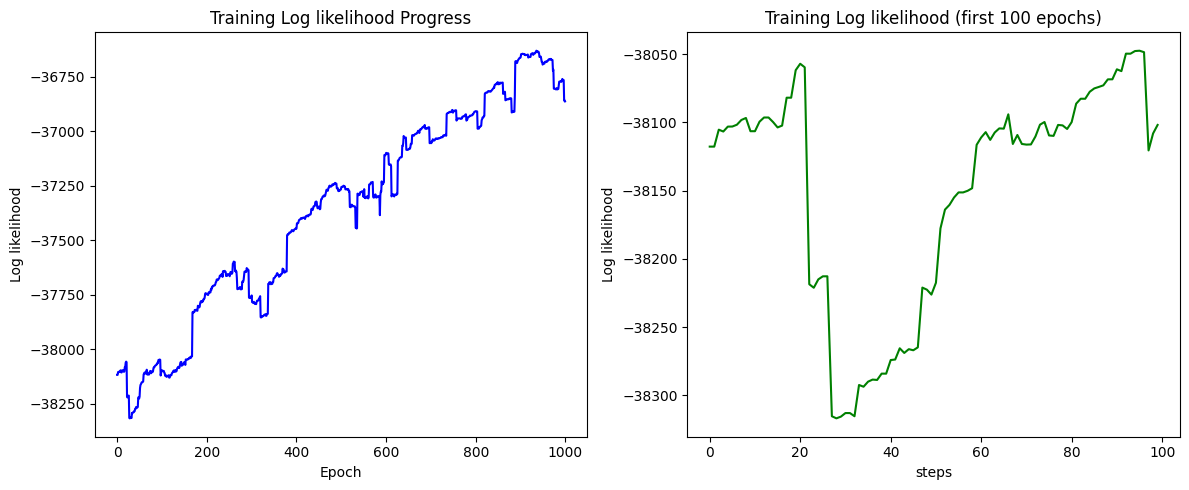

In [ ]:
fig, axes = plt.subplots(1, 2 , figsize=(12,5))

axes[0].plot(model.loss_history, label="Log-likelihood", color="blue")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Log likelihood")
axes[0].set_title("Training Log likelihood Progress")

axes[1].plot(model.loss_history[:100], label="Log-likelihood", color="green")
axes[1].set_xlabel("steps")
axes[1].set_ylabel("Log likelihood")
axes[1].set_title("Training Log likelihood (first 100 epochs)")

plt.tight_layout()
plt.show()

In [ ]:
for _ in range(55):#55
    model.fit(x_data,y)

100%|██████████| 1000/1000 [00:11<00:00, 85.25it/s]


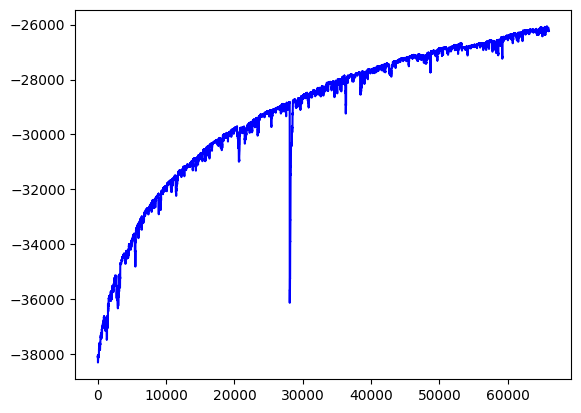

In [ ]:
plt.plot(model.loss_history, label="Log-likelihood", color="blue")

Text(0.5, 1.0, 'Training Log likelihood Progress')

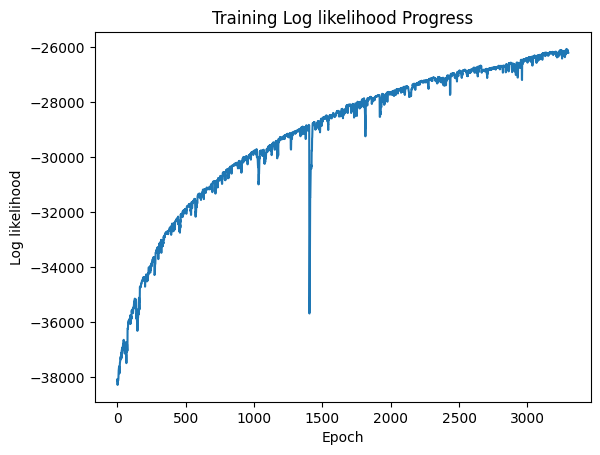

In [ ]:
plt.plot(model.loss_history_2, label="Log-likelihood")
plt.xlabel("Epoch")
plt.ylabel("Log likelihood")
plt.title("Training Log likelihood Progress")

In [ ]:
np.save("weights.npy", model.weights)
np.save("bias.npy", model.bias)

In [ ]:
y_pred = model.prediction(x_data)

In [ ]:
def accuracy(Y,y):
    assert len(Y) == len(y), "Shape mismatch: Y and y must be the same dimensions"
    correct = np.sum(Y == y)
    return correct / len(Y)

In [ ]:
y = final_df.label.values.reshape(-1,1)
print(accuracy(y,y_pred))

0.7743900221810116


In [ ]:
dev_dataset = pd.read_csv(data_path['dev'])

In [ ]:
dev_dataset = dev_dataset.iloc[:,[2,3]]
dev_dataset.head()

,generation,label
0,"I'm not sure what to make of this film, but it...",True
1,As the World looks And looks\n\nThis is the on...,True
2,1 cup thinly sliced leeks\n1 tablespoon olive ...,False
3,A couple of weeks ago my husband and I gave ...,False
4,"Feet pounding the pavement,\nA rhythm of life ...",True


In [ ]:
dev_dataset['generation'] = dev_dataset['generation'].str.lower()

In [ ]:
dev_corpus = [preprocess(doc) for doc in dev_dataset.generation]
tf_matrix_dev, _ = create_sparse_matrix(dev_corpus, dev=True, vocabulary=vocabulary)
dev_tfid = TFID.transform(tf_matrix_dev)

In [ ]:
bias_d = np.ones((dev_tfid.shape[0], 1))
tfid_d_b = hstack([dev_tfid, bias_d])

In [ ]:
y_dev = dev_dataset.label.values.reshape(-1,1)

In [ ]:
dev_pred = model.prediction(tfid_d_b)

In [ ]:
print(accuracy(y_dev,dev_pred))

0.7432


In [ ]:
# testing_data = pd.read_csv(data_path['test'])

In [ ]:
# testing_data.head()

,id,generation
0,159cfc46-20ea-494b-b3c6-24a30ff39683,The objective of this paper is to present an i...
1,b1218846-0934-4617-81f3-9a882748e56e,"Nicole Arsenault-Bishop (born October 28, 1981..."
2,64feb613-72c3-47df-8c17-d3338fc41aba,I didn't expect this to mirror how my ex wife ...
3,a2373d5d-86da-4a46-87f5-703ff60f8c73,Νаrаsіmhаn Мurаlі (bоrn іn Сhеnnаі (Маdrаs) оn...
4,73fc1aee-39fa-4f48-bb23-29014ba82664,"Ryan Smith (born February 22, 1996) is a Ameri..."


In [ ]:
# data = testing_data['generation'].str.lower()
# test_corpus = [preprocess(doc) for doc in data]
# test_data = TFID_model.transform(test_corpus )

In [ ]:
# test_pred = []
# for indx , test_features in enumerate(test_data):
#     x_value = np.dot(test_features ,model.weights) + model.bias
#     test_pred.append( [indx , (1 / (1 + np.exp(-x_value))) >= 0.5] )

In [ ]:
# test_predictions = df = pd.DataFrame(test_pred, columns=["id", "label"])
# test_predictions.head()

,id,label
0,0,True
1,1,True
2,2,False
3,3,False
4,4,False


In [ ]:
# df.to_csv("output.csv", index=False)

# print("CSV file saved as output.csv")

CSV file saved as output.csv
